# Immune Gene Co-expression Modules vs Genera (Recalled Genera)

Data-driven modules of immune genes, tested against genus abundance beyond total bacterial load.

**Genes:** every gene annotated to the defense GO terms (`Defense_go_terms.csv` plus Luke's custom non-self-recognition set) or in the shared flg22-induced set. Genes are **not** filtered on correlation with load, so modules aren't built around bacterial quantity. Genes with median log2(TPM + 1) < `min_median_log2_tpm` are dropped.

**Removing season:** log2(TPM + 1) is centred within each timepoint before clustering. Modules therefore capture plant-to-plant variation at the same timepoint rather than the seasonal trend.

**Clustering:** average-linkage hierarchical clustering on 1 − Pearson r between genes. The tree is cut at `cut_height`, and clusters with at least `min_module_size` genes are kept as modules. At a cut of 0.5, genes in a module are correlated at r ≳ 0.5 on average. Each module is summarised by its eigengene (first principal component of its z-scored genes, signed to follow the module's mean expression).

**Genus tests:** for each module and genus, an OLS model `eigengene ~ timepoint + log10(total load) + log10(genus % + 0.05)`. The genus term asks whether a genus is linked to the module *beyond* how much bacteria is on the plant (`ham16s`). Genera present in at least `min_genus_prevalence` of samples are tested, and p-values are BH-corrected across all module × genus tests.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import contextlib
import io
import statsmodels.api as sm
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform
from statsmodels.stats.multitest import multipletests
import Go_tools

###Define Thresholds
min_median_log2_tpm = 2
cut_height = 0.5
min_module_size = 10
min_genus_prevalence = 0.2
genus_pseudocount = 0.05  # % of reads (the recalled table's detection floor)

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
metadata = metadata.drop(
    columns=[
        "arb.sort",
        "sample-id",
        "Ambiguous Unstranded",
        "Ambiguous Forward",
        "Multimapping",
        "Unmapped Over Mapped",
    ]
)
metadata["Date and Time"] = metadata["date"] + " " + metadata["time"]
luke_time_data_format = "%-m/%-d/%y %-H:%-M"
metadata["Date and Time"] = pd.to_datetime(
    metadata["Date and Time"], format=luke_time_data_format
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426


## Immune genes

In [3]:
go_term_matrix = pd.read_csv(
    "/Users/michael/Data/Reference_data/Arabdidopsis_go_matrix_from_tair_gaf.csv",
    index_col=0,
)
defense_terms = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Defense_go_terms.csv"
)
non_self_recognition_genes = [
    "AT1G02920", "AT1G02930", "AT1G21110", "AT1G21120", "AT1G26380", "AT1G26410",
    "AT1G26420", "AT1G35230", "AT1G64170", "AT1G65500", "AT1G76930", "AT2G19190",
    "AT2G25470", "AT2G30750", "AT2G39200", "AT2G43620", "AT3G46280", "AT4G12490",
    "AT4G12500", "AT4G23140", "AT4G23220", "AT4G28420", "AT5G24110", "AT5G64120",
]
defense_go_terms = [t for t in defense_terms["GO Term ID"] if t in go_term_matrix.columns]
go_defense_genes = set(go_term_matrix.index[go_term_matrix[defense_go_terms].sum(axis=1) > 0]) | set(
    non_self_recognition_genes
)
flg_genes = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/shared_flg_induced_genes.csv"
)
flg_arabidopsis_genes = set(flg_genes["Arabidopsis_thaliana"].dropna().astype(str).str.strip())

immune_genes = sorted((go_defense_genes | flg_arabidopsis_genes) & set(trimmed_transcriptome.columns))
log_expression = np.log2(trimmed_transcriptome[immune_genes] + 1)
log_expression = log_expression.loc[:, log_expression.median() >= min_median_log2_tpm]
print(f"Immune genes in transcriptome: {len(immune_genes)}; expressed (median log2 TPM+1 >= {min_median_log2_tpm}): {log_expression.shape[1]}")

# Remove the seasonal trend: centre each gene within its timepoint, then z-score
centred = log_expression - log_expression.groupby(trimmed_metadata["timepoint"]).transform("mean")
immune_z = (centred - centred.mean()) / centred.std()
immune_z = immune_z.loc[:, immune_z.std() > 0]

Immune genes in transcriptome: 1425; expressed (median log2 TPM+1 >= 2): 691


## Clustering

In [4]:
gene_correlation = np.corrcoef(immune_z.T.to_numpy())
distance = np.clip(1 - gene_correlation, 0, 2)
np.fill_diagonal(distance, 0)
gene_linkage = linkage(squareform(distance, checks=False), method="average")

cluster_labels = pd.Series(fcluster(gene_linkage, cut_height, criterion="distance"), index=immune_z.columns)
cluster_sizes = cluster_labels.value_counts()
kept_clusters = cluster_sizes.index[cluster_sizes >= min_module_size]

# Name modules M1, M2, ... from largest to smallest
module_names = {cluster: f"M{i + 1}" for i, cluster in enumerate(kept_clusters)}
gene_modules = cluster_labels.map(module_names).fillna("Unassigned")
modules = [f"M{i + 1}" for i in range(len(kept_clusters))]

pairs = np.triu_indices_from(gene_correlation, 1)
print(f"Median |r| between immune genes (within timepoint): {np.median(np.abs(gene_correlation[pairs])):.2f}")
print(f"Modules with >= {min_module_size} genes at cut {cut_height}: {len(modules)}")
print(f"Genes assigned to a module: {(gene_modules != 'Unassigned').sum()} of {len(gene_modules)}")

module_summary = pd.DataFrame(
    {
        "n genes": gene_modules.value_counts().reindex(modules),
        "mean within-module r": [
            gene_correlation[np.ix_(gene_modules.values == m, gene_modules.values == m)][
                np.triu_indices((gene_modules == m).sum(), 1)
            ].mean()
            for m in modules
        ],
        "FLG genes": [len(set(gene_modules.index[gene_modules == m]) & flg_arabidopsis_genes) for m in modules],
        "GO-defense genes": [len(set(gene_modules.index[gene_modules == m]) & go_defense_genes) for m in modules],
    }
)
module_summary.round(2)

Median |r| between immune genes (within timepoint): 0.26
Modules with >= 10 genes at cut 0.5: 5
Genes assigned to a module: 214 of 691


,n genes,mean within-module r,FLG genes,GO-defense genes
M1,121,0.56,101,44
M2,34,0.60,24,14
M3,33,0.56,7,26
M4,13,0.62,1,12
M5,13,0.58,0,13


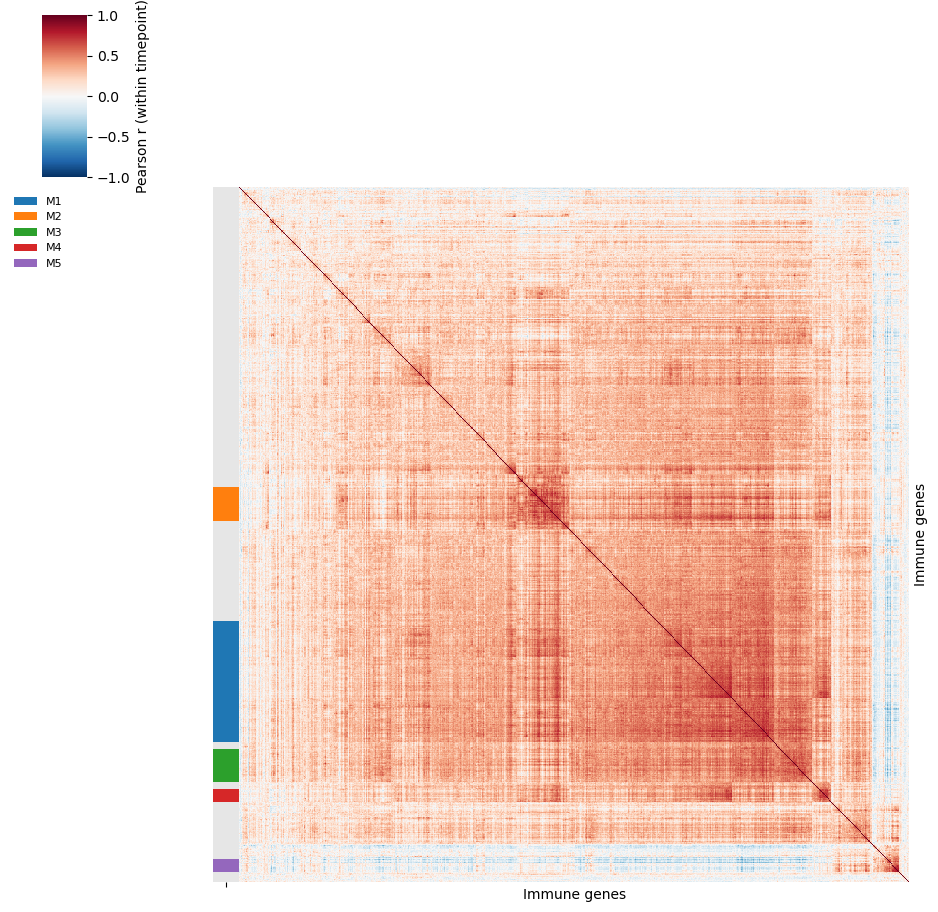

In [5]:
# Gene-gene correlation heatmap, ordered by the clustering, with module colour bar
module_palette = dict(zip(modules, sns.color_palette("tab10", len(modules))))
module_palette["Unassigned"] = (0.9, 0.9, 0.9)
order = dendrogram(gene_linkage, no_plot=True)["leaves"]
ordered_genes = immune_z.columns[order]

g = sns.clustermap(
    pd.DataFrame(gene_correlation, index=immune_z.columns, columns=immune_z.columns).loc[ordered_genes, ordered_genes],
    row_cluster=False,
    col_cluster=False,
    row_colors=gene_modules.loc[ordered_genes].map(module_palette),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False,
    figsize=(9, 9),
    cbar_kws={"label": "Pearson r (within timepoint)"},
)
g.ax_heatmap.set_xlabel("Immune genes")
g.ax_heatmap.set_ylabel("Immune genes")
for m in modules:
    g.ax_row_colors.bar(0, 0, color=module_palette[m], label=m)
g.ax_row_colors.legend(loc="upper left", bbox_to_anchor=(-8, 1), frameon=False, fontsize=8)

## What each module is

In [6]:
marker_genes = {
    "PR1": "AT2G14610", "PR2": "AT3G57260", "PR5": "AT1G75040", "ICS1": "AT1G74710",
    "EDS1": "AT3G48090", "PAD4": "AT3G52430", "NPR1": "AT1G64280",
    "PDF1.2": "AT5G44420", "VSP2": "AT5G24770", "LOX2": "AT3G45140", "JAZ1": "AT1G19180",
    "MYC2": "AT1G32640", "ERF1": "AT3G23240",
    "PAD3": "AT3G26830", "CYP71A13": "AT2G30770", "CYP81F2": "AT5G57220", "MYB51": "AT1G18570",
    "FRK1": "AT2G19190", "NHL10": "AT2G35980", "WRKY29": "AT4G23550", "WRKY33": "AT2G38470",
    "FLS2": "AT5G46330", "BAK1": "AT4G33430", "RBOHD": "AT5G47910",
}
pd.DataFrame(
    {
        "gene": list(marker_genes.values()),
        "module": [
            gene_modules.get(gene, "not expressed / not in immune set") for gene in marker_genes.values()
        ],
    },
    index=pd.Index(list(marker_genes.keys()), name="marker"),
)

,gene,module
marker,,
PR1,AT2G14610,M4
PR2,AT3G57260,M4
PR5,AT1G75040,M4
ICS1,AT1G74710,not expressed / not in immune set
EDS1,AT3G48090,not expressed / not in immune set
PAD4,AT3G52430,M1
NPR1,AT1G64280,Unassigned
PDF1.2,AT5G44420,Unassigned
VSP2,AT5G24770,not expressed / not in immune set


In [7]:
# GO biological-process enrichment of each module, against the clustered immune genes
go_term_names = pd.read_csv("/Users/michael/Data/Reference_data/goterm_names.csv", index_col=0)
background_genes = gene_modules.index.tolist()
go_background = go_term_matrix.reindex(background_genes).fillna(0)
go_background = go_background.loc[:, go_background.sum() >= 3]

module_go = {}
for m in modules:
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        cont_tables = Go_tools.generate_contigency_tables(
            go_annotations=go_background,
            gene_list=gene_modules.index[gene_modules == m].tolist(),
            use_background_genes=True,
            background_genes=background_genes,
        )
        fishers_results = Go_tools.fishers_exact_on_contigency_tables(
            all_go_contigency_tables=cont_tables,
            original_GO_term_panda=go_background,
        )
        corrected = Go_tools.multi_hypothesis_correct_fishers_exact(fishers_results)
    module_go[m] = corrected.merge(go_term_names, left_index=True, right_index=True, how="left").sort_values("P_value")

pd.DataFrame(
    {
        m: {
            "top GO terms (corrected P < 0.05)": "; ".join(
                module_go[m].loc[module_go[m]["P_value"] < 0.05, "x"].head(5).dropna()
            )
            or "none"
        }
        for m in modules
    }
).T

,top GO terms (corrected P < 0.05)
M1,cellular response to hypoxia
M2,extracellular region; plant-type cell wall; cy...
M3,none
M4,systemic acquired resistance; apoplast
M5,cytosolic ribosome; mRNA binding; ribosome bio...


## Module eigengenes

In [8]:
def eigengene(module_genes):
    values = immune_z[module_genes].to_numpy()
    u, s, vt = np.linalg.svd(values - values.mean(axis=0), full_matrices=False)
    score = pd.Series(u[:, 0] * s[0], index=immune_z.index)
    if np.corrcoef(score, immune_z[module_genes].mean(axis=1))[0, 1] < 0:
        score = -score
    return (score - score.mean()) / score.std()


module_eigengenes = pd.DataFrame(
    {m: eigengene(gene_modules.index[gene_modules == m].tolist()) for m in modules}
)
display(module_eigengenes.corr().round(2))

# Relation to the 148-gene load-correlated defense score
defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
module_summary["load-selected defense genes (148 set)"] = [
    len(set(gene_modules.index[gene_modules == m]) & set(defense_gene_list["gene"])) for m in modules
]
module_summary.round(2)

,M1,M2,M3,M4,M5
M1,1.00,0.80,0.84,0.73,-0.20
M2,0.80,1.00,0.57,0.68,-0.01
M3,0.84,0.57,1.00,0.49,-0.12
M4,0.73,0.68,0.49,1.00,0.07
M5,-0.20,-0.01,-0.12,0.07,1.00


,n genes,mean within-module r,FLG genes,GO-defense genes,load-selected defense genes (148 set)
M1,121,0.56,101,44,24
M2,34,0.60,24,14,5
M3,33,0.56,7,26,11
M4,13,0.62,1,12,4
M5,13,0.58,0,13,6


## Microbiome: genus abundance and total load

In [9]:
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Sept_2026_recalled_genera/lic_16S_gen_rab_clean.csv"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]
genus_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Genus", aggfunc="sum", fill_value=0
)
genus_abundance_matrix = genus_abundance_matrix.div(genus_abundance_matrix.sum(axis=1), axis=0) * 100

total_load = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Microbiome/lic2024_ham_16S_ITS.csv", index_col=0
)["ham16s"]

model_samples = trimmed_metadata.index[
    trimmed_metadata["sampID"].isin(genus_abundance_matrix.index)
    & trimmed_metadata["sampID"].map(total_load).notna()
]
sample_genera = genus_abundance_matrix.loc[trimmed_metadata.loc[model_samples, "sampID"]].set_index(model_samples)
tested_genera = sample_genera.columns[(sample_genera > 0).mean() >= min_genus_prevalence]
log_genus = np.log10(sample_genera[tested_genera] + genus_pseudocount)
log_load = np.log10(trimmed_metadata.loc[model_samples, "sampID"].map(total_load))
print(f"Samples with transcriptome, microbiome and load: {len(model_samples)}")
print(f"Genera tested (present in >= {min_genus_prevalence:.0%} of samples): {len(tested_genera)}")

Samples with transcriptome, microbiome and load: 423
Genera tested (present in >= 20% of samples): 89


In [10]:
timepoint_dummies = pd.get_dummies(
    trimmed_metadata.loc[model_samples, "timepoint"], prefix="tp", drop_first=True, dtype=float
)


def fit_module(y, extra):
    X = sm.add_constant(pd.concat([timepoint_dummies, extra], axis=1))
    return sm.OLS(y, X).fit()


# How each module relates to total load on its own
load_rows = []
for m in modules:
    fit = fit_module(module_eigengenes.loc[model_samples, m], log_load.rename("log_load").to_frame())
    load_rows.append({"module": m, "load coef": fit.params["log_load"], "load t": fit.tvalues["log_load"], "load p": fit.pvalues["log_load"]})
module_load = pd.DataFrame(load_rows).set_index("module")
module_load["load q"] = multipletests(module_load["load p"], method="fdr_bh")[1]
module_load.round(4)

,load coef,load t,load p,load q
module,,,,
M1,1.8832,4.0974,0.0001,0.0001
M2,2.1714,4.7665,0.0000,0.0000
M3,1.5479,3.3268,0.0010,0.0012
M4,1.5675,3.3795,0.0008,0.0012
M5,0.6648,1.4104,0.1593,0.1593


In [11]:
# Each module x genus, with total load in the model
association_rows = []
for m in modules:
    y = module_eigengenes.loc[model_samples, m]
    for genus in tested_genera:
        fit = fit_module(
            y,
            pd.DataFrame({"log_load": log_load, "log_genus": log_genus[genus]}),
        )
        association_rows.append(
            {
                "module": m,
                "genus": genus,
                "genus coef": fit.params["log_genus"],
                "genus t": fit.tvalues["log_genus"],
                "genus p": fit.pvalues["log_genus"],
                "load t": fit.tvalues["log_load"],
                "genus prevalence": (sample_genera[genus] > 0).mean(),
            }
        )
module_genus = pd.DataFrame(association_rows)
module_genus["genus q"] = multipletests(module_genus["genus p"], method="fdr_bh")[1]
module_genus.to_csv(f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/immune_module_genus_associations.csv", index=False)
gene_modules.rename("module").to_csv(f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/immune_gene_modules.csv")

print(f"Module x genus tests: {len(module_genus)}; significant (q < 0.05): {(module_genus['genus q'] < 0.05).sum()}")
module_genus.sort_values("genus p").head(25).round(4)

Module x genus tests: 445; significant (q < 0.05): 69


,module,genus,genus coef,genus t,genus p,load t,genus prevalence,genus q
196,M3,g__Caldora,-1.3267,-7.6869,0.0000,-1.4772,0.8085,0.0000
18,M1,g__Caldora,-1.2313,-7.1551,0.0000,-0.5266,0.8085,0.0000
220,M3,g__Kordiimonas,-4.1253,-7.0344,0.0000,-4.1026,1.0000,0.0000
160,M2,g__Pseudomonas,0.8662,6.9973,0.0000,4.7880,1.0000,0.0000
42,M1,g__Kordiimonas,-3.8097,-6.5215,0.0000,-3.2532,1.0000,0.0000
288,M4,g__Chryseobacterium,0.6370,6.3924,0.0000,3.1376,0.9220,0.0000
107,M2,g__Caldora,-1.0922,-6.3159,0.0000,0.4825,0.8085,0.0000
96,M2,g__Aldersonia,1.0753,5.8511,0.0000,4.7713,0.3404,0.0000
338,M4,g__Pseudomonas,0.7491,5.8362,0.0000,3.2953,1.0000,0.0000
7,M1,g__Aldersonia,1.0387,5.5802,0.0000,4.0659,0.3404,0.0000


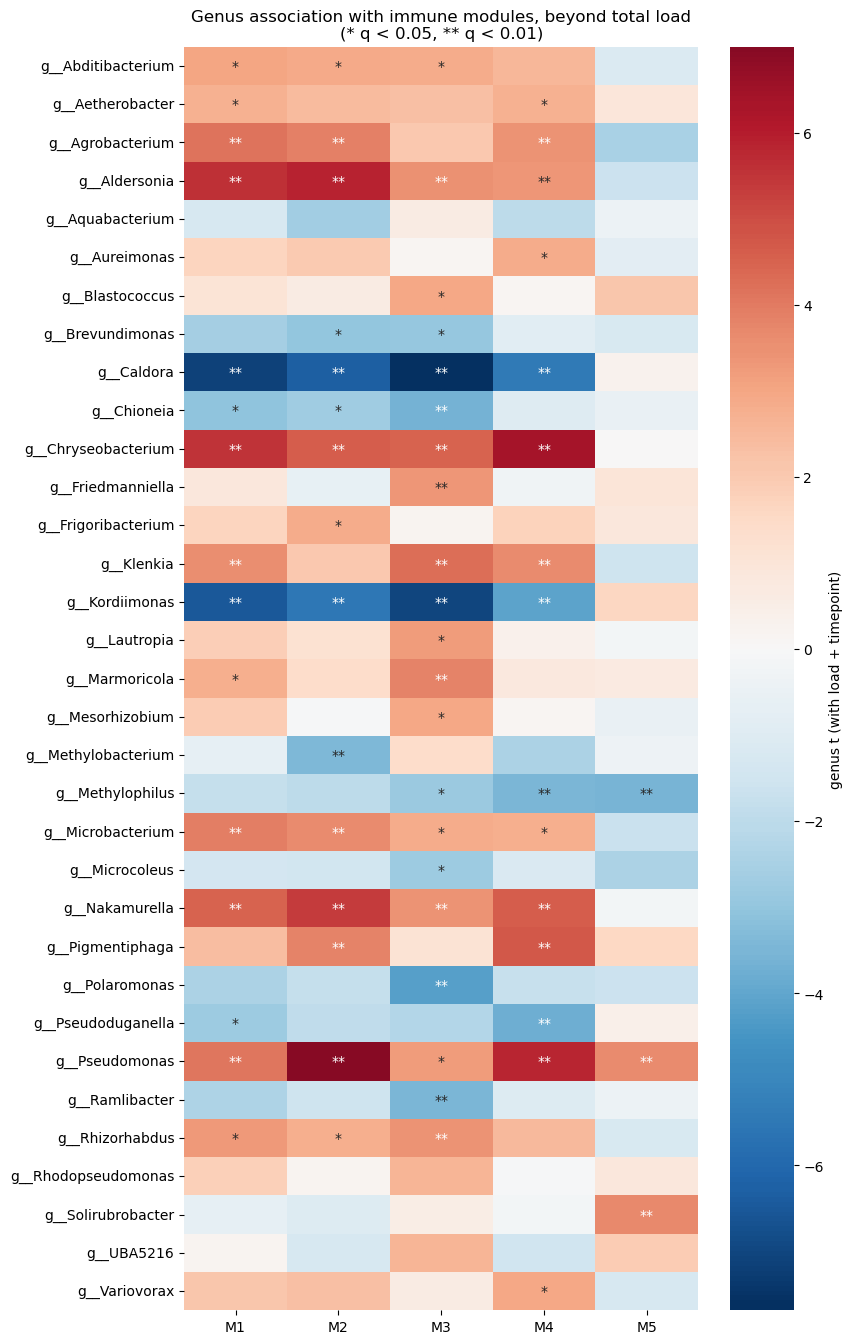

In [12]:
t_matrix = module_genus.pivot(index="genus", columns="module", values="genus t")[modules]
q_matrix = module_genus.pivot(index="genus", columns="module", values="genus q")[modules]
# Show genera with at least one nominal hit
show = t_matrix.index[(module_genus.pivot(index="genus", columns="module", values="genus p") < 0.01).any(axis=1)]
if len(show) == 0:
    print("No module x genus pairs with p < 0.01")
else:
    annot = q_matrix.loc[show].map(lambda q: "**" if q < 0.01 else "*" if q < 0.05 else "")
    fig, ax = plt.subplots(figsize=(1.1 * len(modules) + 3, 0.35 * len(show) + 2))
    fig.patch.set_facecolor("white")
    sns.heatmap(
        t_matrix.loc[show],
        cmap="RdBu_r",
        center=0,
        annot=annot,
        fmt="",
        cbar_kws={"label": "genus t (with load + timepoint)"},
        ax=ax,
    )
    ax.set_title("Genus association with immune modules, beyond total load\n(* q < 0.05, ** q < 0.01)")
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.tight_layout()

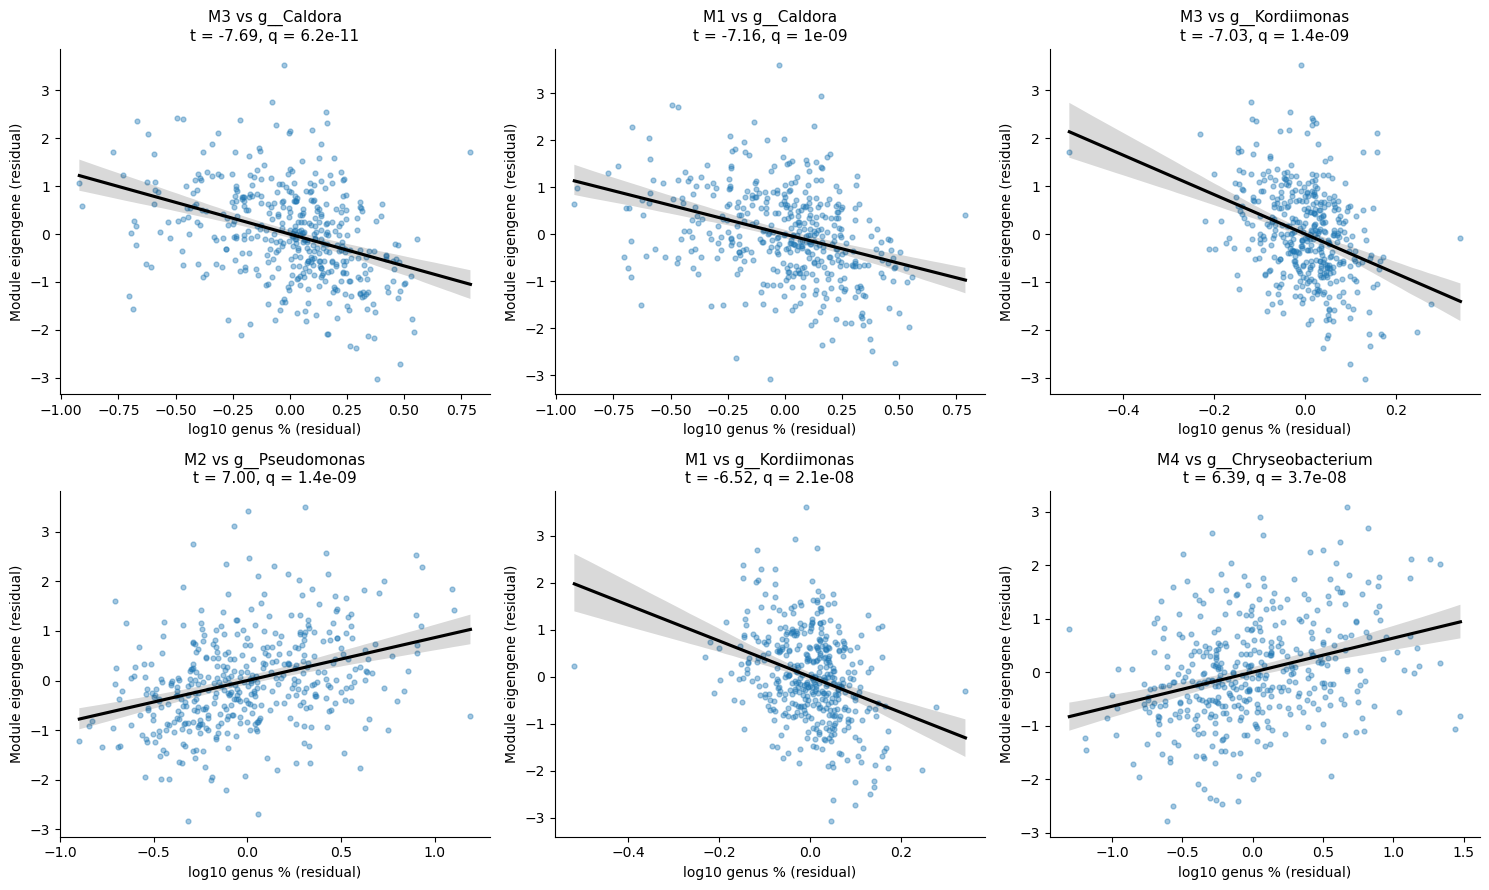

In [13]:
# Scatter of the strongest pairs, after removing timepoint and load from both axes
top_pairs = module_genus.sort_values("genus p").head(6)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.patch.set_facecolor("white")
covariates = sm.add_constant(pd.concat([timepoint_dummies, log_load.rename("log_load")], axis=1))
for ax, (_, row) in zip(axes.flatten(), top_pairs.iterrows()):
    y_resid = sm.OLS(module_eigengenes.loc[model_samples, row["module"]], covariates).fit().resid
    x_resid = sm.OLS(log_genus[row["genus"]], covariates).fit().resid
    sns.regplot(x=x_resid, y=y_resid, ax=ax, scatter_kws={"alpha": 0.4, "s": 12}, line_kws={"color": "black"})
    ax.set_title(f"{row['module']} vs {row['genus']}\nt = {row['genus t']:.2f}, q = {row['genus q']:.2g}", fontsize=11)
    ax.set_xlabel("log10 genus % (residual)")
    ax.set_ylabel("Module eigengene (residual)")
    sns.despine(ax=ax)
plt.tight_layout()

## Shared immune axis vs module-specific associations

The module eigengenes are strongly correlated with each other, so most module × genus hits above reflect one shared axis: the first principal component of all clustered immune genes, computed within timepoint. This section:

1. Measures how much of the variation that axis explains, and whether it tracks sequencing metrics (library size), which would point to a partly technical source.
2. Tests which genera are linked to the shared axis itself.
3. Re-tests each module × genus pair with the shared axis in the model (`eigengene ~ timepoint + log10 load + shared axis + log10 genus`), so only associations specific to a module remain. A second version also adds log10 total reads, in case the shared axis doesn't fully capture library-size effects.

In [14]:
u, s, vt = np.linalg.svd(immune_z.to_numpy() - immune_z.to_numpy().mean(axis=0), full_matrices=False)
shared_axis = pd.Series(u[:, 0] * s[0], index=immune_z.index)
if np.corrcoef(shared_axis, immune_z.mean(axis=1))[0, 1] < 0:
    shared_axis = -shared_axis
shared_axis = (shared_axis - shared_axis.mean()) / shared_axis.std()
print(f"Shared immune axis (PC1) explains {s[0] ** 2 / (s ** 2).sum():.0%} of within-timepoint variance")
print("Module eigengene correlation with the shared axis:")
print(module_eigengenes.corrwith(shared_axis).round(2).to_string())

# Within-timepoint correlation with sequencing metrics and load
log_total_reads = np.log10(trimmed_metadata["Total Reads"].astype(float))
within = lambda values: values - values.groupby(trimmed_metadata.loc[values.index, "timepoint"]).transform("mean")
print("\nShared axis vs (within timepoint):")
print(f"  log10 total reads: r = {np.corrcoef(shared_axis, within(log_total_reads))[0, 1]:.2f}")
print(f"  log10 unmapped reads: r = {np.corrcoef(shared_axis, within(np.log10(trimmed_metadata['Unmapped'].astype(float).clip(lower=1))))[0, 1]:.2f}")
print(f"  log10 ham16s load: r = {np.corrcoef(shared_axis.loc[model_samples], within(log_load))[0, 1]:.2f}")

Shared immune axis (PC1) explains 30% of within-timepoint variance
Module eigengene correlation with the shared axis:
M1    0.98
M2    0.81
M3    0.89
M4    0.69
M5   -0.12

Shared axis vs (within timepoint):
  log10 total reads: r = -0.14
  log10 unmapped reads: r = -0.09
  log10 ham16s load: r = 0.20


In [15]:
# Genera linked to the shared axis itself (beyond load, within timepoint)
shared_rows = []
for genus in tested_genera:
    fit = fit_module(
        shared_axis.loc[model_samples],
        pd.DataFrame({"log_load": log_load, "log_genus": log_genus[genus]}),
    )
    shared_rows.append({"genus": genus, "genus t": fit.tvalues["log_genus"], "genus p": fit.pvalues["log_genus"]})
shared_axis_genus = pd.DataFrame(shared_rows)
shared_axis_genus["genus q"] = multipletests(shared_axis_genus["genus p"], method="fdr_bh")[1]
print(f"Genera linked to the shared axis (q < 0.05): {(shared_axis_genus['genus q'] < 0.05).sum()} of {len(shared_axis_genus)}")
shared_axis_genus.sort_values("genus p").head(20).round(5)

Genera linked to the shared axis (q < 0.05): 18 of 89


,genus,genus t,genus p,genus q
18,g__Caldora,-7.66627,0.00000,0.00000
42,g__Kordiimonas,-6.81709,0.00000,0.00000
21,g__Chryseobacterium,5.65469,0.00000,0.00000
7,g__Aldersonia,5.31702,0.00000,0.00000
71,g__Pseudomonas,4.77853,0.00000,0.00005
60,g__Nakamurella,4.71800,0.00000,0.00005
41,g__Klenkia,3.93512,0.00010,0.00125
54,g__Microbacterium,3.90492,0.00011,0.00125
20,g__Chioneia,-3.69698,0.00025,0.00249
6,g__Agrobacterium,3.66219,0.00029,0.00255


In [16]:
# Module-specific associations: shared axis in the model (and a version adding library size)
specific_rows = []
for m in modules:
    y = module_eigengenes.loc[model_samples, m]
    for genus in tested_genera:
        base = pd.DataFrame(
            {
                "log_load": log_load,
                "shared_axis": shared_axis.loc[model_samples],
                "log_genus": log_genus[genus],
            }
        )
        fit = fit_module(y, base)
        fit_reads = fit_module(y, base.assign(log_total_reads=log_total_reads.loc[model_samples]))
        specific_rows.append(
            {
                "module": m,
                "genus": genus,
                "genus t": fit.tvalues["log_genus"],
                "genus p": fit.pvalues["log_genus"],
                "genus t (+ reads)": fit_reads.tvalues["log_genus"],
                "genus p (+ reads)": fit_reads.pvalues["log_genus"],
            }
        )
module_specific = pd.DataFrame(specific_rows)
module_specific["genus q"] = multipletests(module_specific["genus p"], method="fdr_bh")[1]
module_specific["genus q (+ reads)"] = multipletests(module_specific["genus p (+ reads)"], method="fdr_bh")[1]
module_specific.to_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/immune_module_genus_associations_module_specific.csv", index=False
)
print(
    f"Module-specific pairs (q < 0.05): {(module_specific['genus q'] < 0.05).sum()}; "
    f"also adjusting for library size: {(module_specific['genus q (+ reads)'] < 0.05).sum()}"
)
module_specific.sort_values("genus p").head(20).round(4)

Module-specific pairs (q < 0.05): 33; also adjusting for library size: 32


,module,genus,genus t,genus p,genus t (+ reads),genus p (+ reads),genus q,genus q (+ reads)
141,M2,g__Methylobacterium,-5.2116,0.0000,-4.7790,0.0000,0.0001,0.0004
160,M2,g__Pseudomonas,5.0913,0.0000,4.9310,0.0000,0.0001,0.0003
264,M3,g__UBA5216,4.9637,0.0000,5.0298,0.0000,0.0001,0.0003
206,M3,g__Friedmanniella,4.9554,0.0000,4.4190,0.0000,0.0001,0.0012
427,M5,g__Pseudomonas,4.5659,0.0000,4.5142,0.0000,0.0006,0.0010
218,M3,g__Kineosporia,4.2545,0.0000,3.9853,0.0001,0.0020,0.0045
335,M4,g__Pigmentiphaga,4.1360,0.0000,3.9020,0.0001,0.0028,0.0056
409,M5,g__Methylophilus,-4.0212,0.0001,-3.9926,0.0001,0.0039,0.0045
230,M3,g__Methylobacterium,3.9798,0.0001,3.3005,0.0011,0.0041,0.0234
236,M3,g__Motilibacter,3.9196,0.0001,4.2935,0.0000,0.0047,0.0017


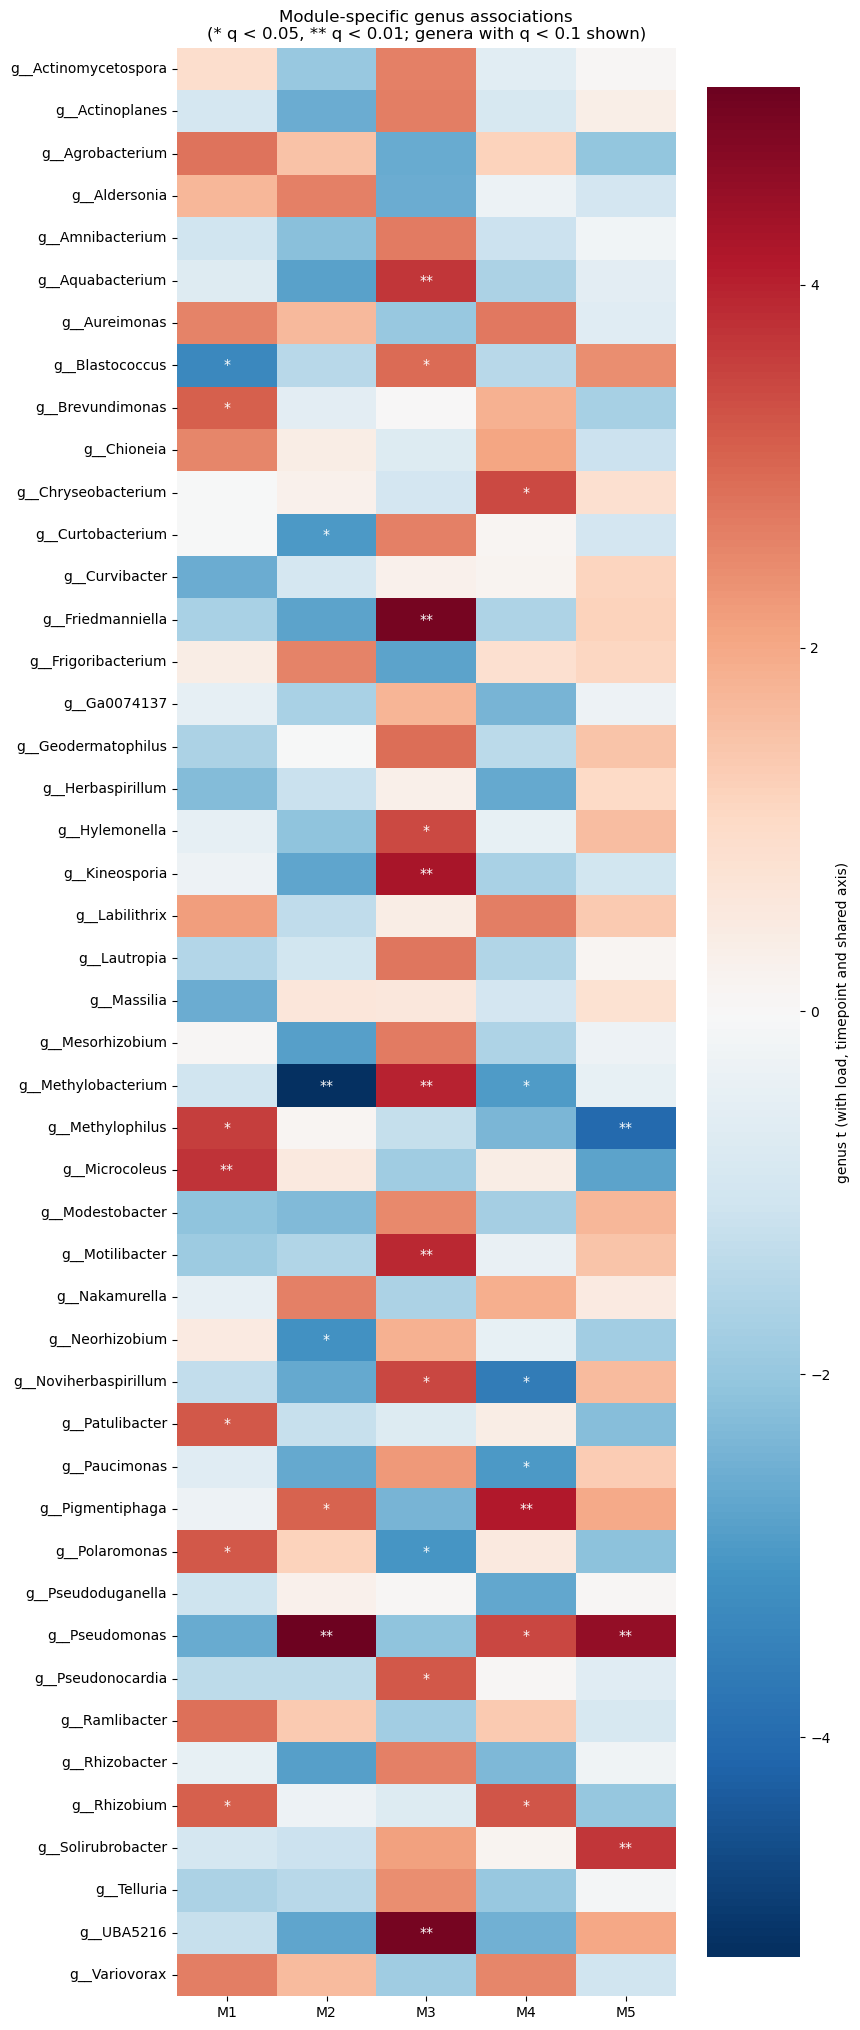

In [17]:
specific_t = module_specific.pivot(index="genus", columns="module", values="genus t")[modules]
specific_q = module_specific.pivot(index="genus", columns="module", values="genus q")[modules]
show = specific_t.index[(specific_q < 0.1).any(axis=1)]
if len(show) == 0:
    print("No module-specific pairs at q < 0.1")
else:
    fig, ax = plt.subplots(figsize=(1.1 * len(modules) + 3, 0.4 * len(show) + 2))
    fig.patch.set_facecolor("white")
    sns.heatmap(
        specific_t.loc[show],
        cmap="RdBu_r",
        center=0,
        annot=specific_q.loc[show].map(lambda q: "**" if q < 0.01 else "*" if q < 0.05 else ""),
        fmt="",
        cbar_kws={"label": "genus t (with load, timepoint and shared axis)"},
        ax=ax,
    )
    ax.set_title("Module-specific genus associations\n(* q < 0.05, ** q < 0.01; genera with q < 0.1 shown)")
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.tight_layout()